# Eventos del maíz y Gruma: cruce de datos bursátiles con SNIIM y DGSIAP

## Pregunta central
¿Los eventos importantes del maíz en México y en el mundo se ven reflejados al mismo tiempo
en el precio del maíz (SNIIM), en la producción (DGSIAP) y en el rendimiento de la acción de
Gruma (GRUMAB.MX)?

La idea es poner los tres datasets en una misma línea de tiempo, marcar los eventos grandes
y ver qué se mueve y qué no. El alcance es descriptivo: si algo coincide no significa que uno
cause al otro, y si no se ve nada también es un hallazgo.

## Carga de los datos

Usamos tres fuentes:
- **Yahoo Finance:** cierre diario ajustado de Gruma, lo llevamos a fin de mes.
- **SNIIM:** precio mensual del maíz blanco en cinco mercados mayoristas (MXN/kg).
- **DGSIAP:** producción anual de *maíz grano* por estado, de 2018 a 2025.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# Ubicamos la raíz desde el repositorio o desde notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

ruta_figuras = raiz / "reports" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

COLOR_GRUMA = "#2a78d6"
COLOR_MAIZ = "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})

### Gruma: cierre a fin de mes y rendimiento mensual

In [2]:
gruma = pd.read_parquet(raiz / "data" / "raw" / "RendimientoYahoo" / "GRUMAB_MX.parquet")["Close"]
gruma.index = gruma.index.tz_localize(None)

# Último cierre de cada mes; usamos el primer día del mes como etiqueta para empatar con el SNIIM.
gruma_mes = gruma.resample("MS").last().loc["2013":"2025"]
print(f"Meses de Gruma: {len(gruma_mes)} ({gruma_mes.index.min():%Y-%m} a {gruma_mes.index.max():%Y-%m})")
gruma_mes.tail()

Meses de Gruma: 156 (2013-01 a 2025-12)


Date
2025-08-01    314.879456
2025-09-01    334.634247
2025-10-01    310.172302
2025-11-01    319.458282
2025-12-01    305.135040
Freq: MS, Name: Close, dtype: float64

### SNIIM: precio del maíz blanco por mercado

Siguiendo la libreta de cobertura del SNIIM, primero promediamos los orígenes de cada mercado
y luego tomamos la **mediana entre los cinco mercados** como precio nacional. La mediana
evita que un mercado caro (Guadalupe en 2022) jale todo el promedio.

In [3]:
sniim = pd.read_csv(raiz / "data" / "processed" / "sniim_maiz_blanco_mensual.csv",
                    parse_dates=["fecha"])

precio_mercado = sniim.groupby(["fecha", "mercado"])["precio_mxn_kg"].mean().unstack()
precio_nacional = precio_mercado.median(axis=1)
print("Meses sin precio en ningún mercado:", precio_nacional.isna().sum())
precio_mercado.resample("YS").mean().round(2)

Meses sin precio en ningún mercado: 1


mercado,Culiacán,Guadalajara,Guadalupe,Hermosillo,Iztapalapa
fecha,,,,,
2013-01-01,4.31,5.06,6.03,5.79,5.36
2014-01-01,4.45,4.48,5.66,5.48,4.97
2015-01-01,3.88,4.76,5.53,5.33,4.96
2016-01-01,4.15,5.27,5.63,5.61,5.73
2017-01-01,4.36,5.34,5.70,5.86,5.90
2018-01-01,4.70,5.35,6.04,5.98,6.12
2019-01-01,5.25,5.53,6.20,7.50,6.60
2020-01-01,5.72,6.06,7.92,7.43,6.58
2021-01-01,6.99,7.67,10.47,7.95,8.80


El precio del maíz pasó de unos 5 MXN/kg en 2013 a más de 10 MXN/kg en 2022–2023, es decir,
se duplicó. Junio de 2020 queda sin precio en todos los mercados, como ya se había visto en el
EDA del SNIIM.

### DGSIAP: producción anual de maíz grano

Los archivos de 2018–2020 nombran algunas columnas distinto (`Nomcultivo Sin Um`, `Precio`),
así que las renombramos. `Volumenproduccion` viene como texto en algunos años, la forzamos a número.

In [4]:
renombres = {"Nomcultivo Sin Um": "Nomcultivo", "Precio": "Preciomediorural"}
columnas_num = ["Sembrada", "Siniestrada", "Volumenproduccion", "Valorproduccion"]

anios = []
for archivo in sorted((raiz / "data" / "raw" / "DGSIAP").glob("*.csv")):
    tabla = pd.read_csv(archivo, index_col=0, low_memory=False).rename(columns=renombres)
    tabla = tabla[tabla["Nomcultivo"].str.strip() == "Maíz grano"].copy()
    for columna in columnas_num:
        tabla[columna] = pd.to_numeric(tabla[columna].astype(str).str.replace(",", ""), errors="coerce")
    anios.append(tabla)
maiz = pd.concat(anios)

produccion = maiz.groupby("Anio").agg(
    produccion_mt=("Volumenproduccion", "sum"),
    valor=("Valorproduccion", "sum"),
    sembrada_mha=("Sembrada", "sum"),
    siniestrada_mha=("Siniestrada", "sum"),
)
# Precio medio rural ponderado por volumen (MXN por tonelada).
produccion["precio_rural_mxn_t"] = produccion["valor"] / produccion["produccion_mt"]
produccion["produccion_sinaloa_mt"] = (
    maiz[maiz["Nomestado"] == "Sinaloa"].groupby("Anio")["Volumenproduccion"].sum()
)
produccion[["produccion_mt", "produccion_sinaloa_mt"]] /= 1e6
produccion[["sembrada_mha", "siniestrada_mha"]] /= 1e6
produccion = produccion.drop(columns="valor")
produccion.round(2)

,produccion_mt,sembrada_mha,siniestrada_mha,precio_rural_mxn_t,produccion_sinaloa_mt
Anio,,,,,
2018,27.17,7.37,0.24,3859.55,5.82
2019,27.23,7.16,0.47,3902.04,6.44
2020,27.42,7.47,0.32,4190.08,6.30
2021,27.50,7.31,0.17,5403.01,5.54
2022,26.55,6.90,0.09,6481.43,5.31
2023,27.55,6.94,0.50,6256.04,6.66
2024,24.33,6.66,0.09,5685.58,3.37
2025,24.42,6.76,0.10,5182.76,2.28


Producción en millones de toneladas y superficie en millones de hectáreas. La producción
nacional se mantuvo alrededor de 27 Mt hasta 2023 y cayó a ~24 Mt en 2024–2025. La caída
viene casi toda de **Sinaloa**, que pasó de 6.7 Mt en 2023 a 2.3 Mt en 2025.

## Línea de tiempo de eventos del maíz

Investigamos noticias y eventos grandes entre 2013 y 2025. Los separamos en **México** y
**Mundo** y anotamos por qué canal podrían afectar a Gruma: el costo del maíz, la regulación
o el tipo de cambio (más de la mitad de las ventas de Gruma vienen de EU, así que el peso
también importa).

In [5]:
eventos = pd.DataFrame([
    ("2016-11-08", "Mundo", "Trump gana la elección en EU; amenaza al TLCAN", "tipo de cambio / comercio"),
    ("2017-08-16", "Mundo", "Inicia la renegociación del TLCAN", "comercio"),
    ("2019-01-18", "México", "Se crea Segalmex y los precios de garantía al maíz", "precio del maíz"),
    ("2020-03-11", "Mundo", "OMS declara pandemia de COVID-19", "demanda / tipo de cambio"),
    ("2020-12-31", "México", "Decreto contra glifosato y maíz transgénico", "regulación"),
    ("2022-02-24", "Mundo", "Invasión rusa a Ucrania; granos en máximos", "costo del maíz"),
    ("2022-05-04", "México", "PACIC: arancel cero a importación de granos", "costo del maíz"),
    ("2023-02-13", "México", "Nuevo decreto: sin maíz transgénico para tortilla", "regulación"),
    ("2024-11-01", "México", "Sequía en Sinaloa: ciclo OI 24-25 con ~1/3 de la siembra", "oferta de maíz"),
    ("2024-12-20", "Mundo", "Panel del T-MEC falla a favor de EU sobre maíz transgénico", "regulación"),
    ("2025-04-02", "Mundo", "EU anuncia aranceles generales a importaciones", "comercio / tipo de cambio"),
    ("2025-10-29", "México", "Paro de productores; precio de garantía de 6,950 MXN/t", "precio del maíz"),
], columns=["fecha", "ambito", "evento", "canal"])
eventos["fecha"] = pd.to_datetime(eventos["fecha"])
eventos

,fecha,ambito,evento,canal
0,2016-11-08,Mundo,Trump gana la elección en EU; amenaza al TLCAN,tipo de cambio / comercio
1,2017-08-16,Mundo,Inicia la renegociación del TLCAN,comercio
2,2019-01-18,México,Se crea Segalmex y los precios de garantía al ...,precio del maíz
3,2020-03-11,Mundo,OMS declara pandemia de COVID-19,demanda / tipo de cambio
4,2020-12-31,México,Decreto contra glifosato y maíz transgénico,regulación
5,2022-02-24,Mundo,Invasión rusa a Ucrania; granos en máximos,costo del maíz
6,2022-05-04,México,PACIC: arancel cero a importación de granos,costo del maíz
7,2023-02-13,México,Nuevo decreto: sin maíz transgénico para tortilla,regulación
8,2024-11-01,México,Sequía en Sinaloa: ciclo OI 24-25 con ~1/3 de ...,oferta de maíz
9,2024-12-20,Mundo,Panel del T-MEC falla a favor de EU sobre maíz...,regulación


Fuentes principales: notas de prensa (El Imparcial, Publimetro, Forbes, Infobae, Luz Noticias)
y comunicados oficiales. Las fechas de la sequía de Sinaloa son aproximadas porque es un
proceso, no un día.

## Las tres series en la misma línea de tiempo

Ponemos Gruma y el precio del maíz en base 100 (enero 2013) y marcamos los eventos.

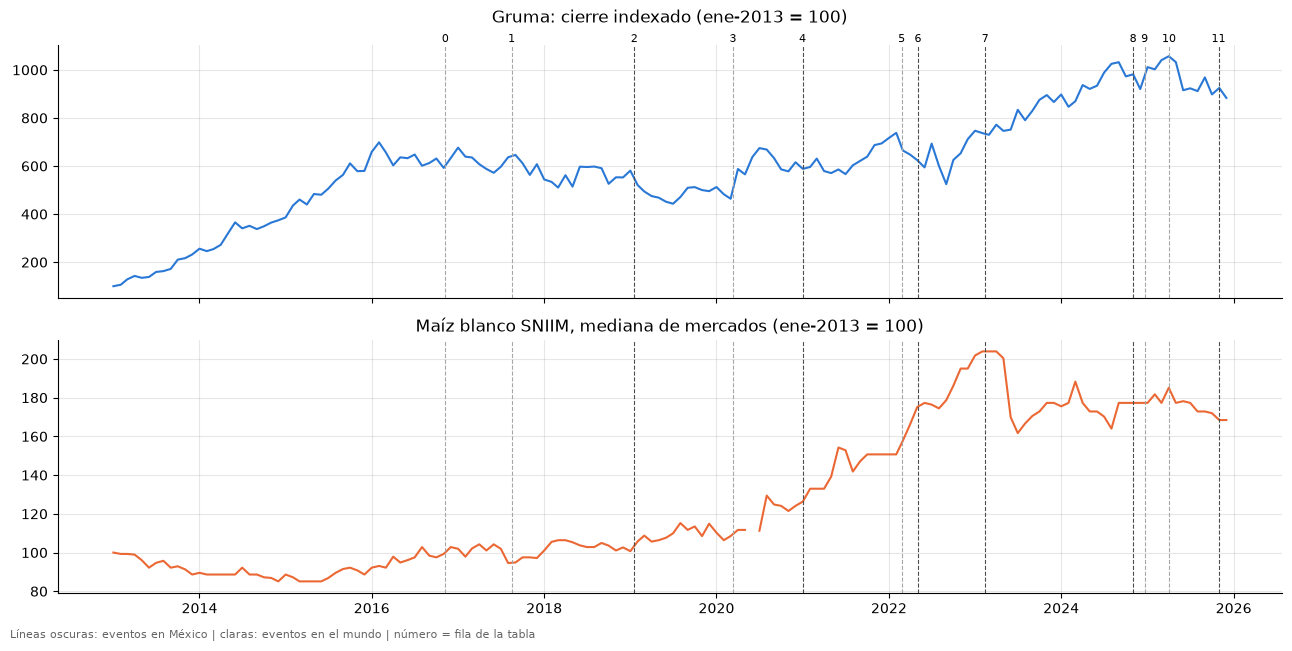

In [6]:
indice = pd.DataFrame({
    "Gruma": 100 * gruma_mes / gruma_mes.iloc[0],
    "Maíz SNIIM": 100 * precio_nacional / precio_nacional.iloc[0],
})

# Dos paneles: Gruma creció ~10 veces y en un solo eje aplastaría la serie del maíz.
fig, ejes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ejes[0].plot(indice.index, indice["Gruma"], color=COLOR_GRUMA)
ejes[0].set_title("Gruma: cierre indexado (ene-2013 = 100)", pad=16)
ejes[1].plot(indice.index, indice["Maíz SNIIM"], color=COLOR_MAIZ)
ejes[1].set_title("Maíz blanco SNIIM, mediana de mercados (ene-2013 = 100)")
for eje in ejes:
    for i, fila in eventos.iterrows():
        color = "0.3" if fila["ambito"] == "México" else "0.65"
        eje.axvline(fila["fecha"], color=color, ls="--", lw=0.8)
for i, fila in eventos.iterrows():
    ejes[0].text(fila["fecha"], ejes[0].get_ylim()[1], str(i), ha="center", va="bottom", fontsize=8)
fig.text(0.01, 0.01, "Líneas oscuras: eventos en México | claras: eventos en el mundo | número = fila de la tabla",
         fontsize=8, color="0.4")
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(ruta_figuras / "cruce_eventos_gruma_maiz.png", dpi=150)
plt.show()

**Hallazgo.** Las dos series suben en el largo plazo, pero no al mismo tiempo:
- Gruma hizo casi todo su crecimiento en **2013–2015**, cuando el maíz estaba barato y estable.
- El maíz se disparó en **2021–2022** (pandemia + Ucrania) y Gruma en esos años apenas se movió.
- Cuando el maíz bajó en 2023, Gruma subió. Eso va en la dirección esperada (insumo más
  barato = mejor margen), pero es un solo episodio.

## ¿Qué pasó alrededor de cada evento?

Para cada evento medimos el cambio de Gruma y del precio del maíz en los **3 meses
siguientes**. Para saber si es un movimiento "raro" lo comparamos con todos los periodos de
3 meses de 2013–2025: si cae por debajo del percentil 10 o arriba del 90 lo marcamos.

In [7]:
cambio_3m = pd.DataFrame({
    "gruma": gruma_mes.shift(-3) / gruma_mes - 1,
    "maiz": precio_nacional.shift(-3) / precio_nacional - 1,
})
p10, p90 = cambio_3m.quantile(0.10), cambio_3m.quantile(0.90)
print("Percentiles 10 y 90 de cualquier ventana de 3 meses:")
print(pd.DataFrame({"p10": p10, "p90": p90}).round(3), "\n")


def etiqueta(valor, serie):
    if pd.isna(valor):
        return "sin dato"
    if valor <= p10[serie]:
        return "baja fuerte"
    if valor >= p90[serie]:
        return "alza fuerte"
    return "normal"


ventanas = eventos[["fecha", "ambito", "evento"]].copy()
mes_evento = ventanas["fecha"].dt.to_period("M").dt.to_timestamp()
ventanas["gruma_3m"] = cambio_3m["gruma"].reindex(mes_evento).values
ventanas["maiz_3m"] = cambio_3m["maiz"].reindex(mes_evento).values
ventanas["gruma"] = [etiqueta(v, "gruma") for v in ventanas["gruma_3m"]]
ventanas["maiz"] = [etiqueta(v, "maiz") for v in ventanas["maiz_3m"]]
ventanas.round({"gruma_3m": 3, "maiz_3m": 3})

Percentiles 10 y 90 de cualquier ventana de 3 meses:
         p10    p90
gruma -0.102  0.205
maiz  -0.043  0.081 



,fecha,ambito,evento,gruma_3m,maiz_3m,gruma,maiz
0,2016-11-08,Mundo,Trump gana la elección en EU; amenaza al TLCAN,0.079,-0.014,normal,normal
1,2017-08-16,Mundo,Inicia la renegociación del TLCAN,-0.115,0.031,baja fuerte,normal
2,2019-01-18,México,Se crea Segalmex y los precios de garantía al ...,-0.182,0.049,baja fuerte,normal
3,2020-03-11,Mundo,OMS declara pandemia de COVID-19,0.374,NaN,alza fuerte,sin dato
4,2020-12-31,México,Decreto contra glifosato y maíz transgénico,0.025,0.071,normal,normal
5,2022-02-24,Mundo,Invasión rusa a Ucrania; granos en máximos,-0.154,0.162,baja fuerte,alza fuerte
6,2022-05-04,México,PACIC: arancel cero a importación de granos,-0.039,-0.004,normal,normal
7,2023-02-13,México,Nuevo decreto: sin maíz transgénico para tortilla,0.012,-0.017,normal,normal
8,2024-11-01,México,Sequía en Sinaloa: ciclo OI 24-25 con ~1/3 de ...,0.021,0.025,normal,normal
9,2024-12-20,Mundo,Panel del T-MEC falla a favor de EU sobre maíz...,0.131,0.000,normal,normal


**Hallazgo.**
- El único evento donde **las dos series se mueven fuerte a la vez** es la invasión a Ucrania
  (feb-2022): el maíz sube 16 % en 3 meses y Gruma cae 15 %. Es justo la relación esperada
  (sube el insumo, baja la acción), pero es un solo caso.
- Gruma tiene movimientos fuertes en otros 4 eventos (TLCAN, Segalmex, COVID, aranceles 2025),
  pero en ninguno el maíz se movió fuera de lo normal. Esos movimientos responden a otra cosa:
  mercado general, comercio con EU y tipo de cambio.
- Los eventos **regulatorios** (decretos de transgénicos, panel del T-MEC) y la **sequía de
  Sinaloa** no dejan huella en ninguna de las dos series.
- El paro de productores de oct-2025 queda fuera de la ventana de datos del SNIIM.

## Correlación mes a mes: rendimiento de Gruma vs. cambio del maíz

Más allá de los eventos, medimos si en general los meses en que sube el maíz son meses malos
para Gruma. Probamos el mismo mes y con rezago de 1 a 3 meses (el maíz se mueve primero y
Gruma después).

In [8]:
mensual = pd.DataFrame({
    "gruma": gruma_mes.pct_change(),
    "maiz": precio_nacional.pct_change(),
})

filas = []
for rezago in range(0, 4):
    datos = pd.DataFrame({"gruma": mensual["gruma"], "maiz": mensual["maiz"].shift(rezago)}).dropna()
    r = stats.spearmanr(datos["gruma"], datos["maiz"])
    filas.append({"rezago_meses": rezago, "n": len(datos), "spearman": r.statistic, "p_valor": r.pvalue})
pd.DataFrame(filas).round(3)

,rezago_meses,n,spearman,p_valor
0,0,153,-0.121,0.136
1,1,152,0.047,0.568
2,2,151,-0.042,0.605
3,3,150,-0.085,0.302


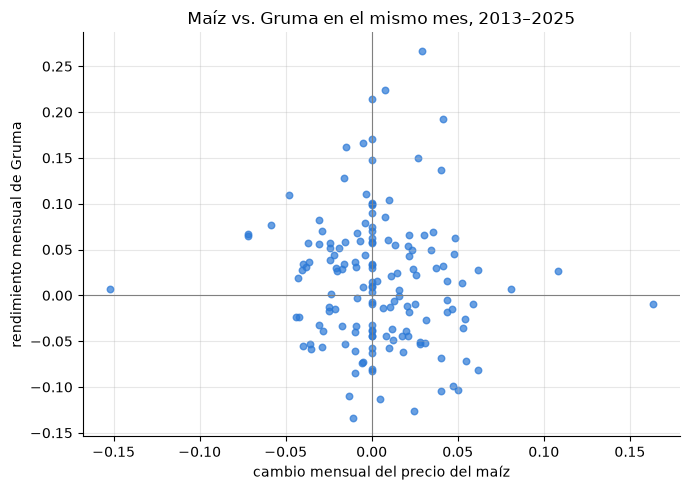

In [9]:
datos = mensual.dropna()

fig, eje = plt.subplots(figsize=(7, 5))
eje.scatter(datos["maiz"], datos["gruma"], s=22, color=COLOR_GRUMA, alpha=0.7)
eje.axhline(0, color="0.5", lw=0.8)
eje.axvline(0, color="0.5", lw=0.8)
eje.set_xlabel("cambio mensual del precio del maíz")
eje.set_ylabel("rendimiento mensual de Gruma")
eje.set_title("Maíz vs. Gruma en el mismo mes, 2013–2025")
fig.tight_layout()
plt.show()

**Hallazgo.** No se descubrió una relación. Ninguna correlación es significativa (todos los
p-valores > 0.1) y la nube de puntos es redonda. En el mismo mes aparece un -0.12 que va en la
dirección esperada, pero es muy débil. Mes a mes, el cambio del precio regional del maíz no
dice nada útil del rendimiento de Gruma.

## Vista anual con la producción (DGSIAP)

El DGSIAP es anual y solo cubre 2018–2025, así que juntamos todo por año: producción,
precio medio rural, precio SNIIM promedio y rendimiento anual de Gruma.

In [10]:
anual = produccion[["produccion_mt", "produccion_sinaloa_mt", "precio_rural_mxn_t"]].copy()
anual["precio_sniim_mxn_kg"] = precio_nacional.groupby(precio_nacional.index.year).mean()
anual["rendimiento_gruma"] = gruma_mes.groupby(gruma_mes.index.year).last().pct_change()
anual.round(3)

,produccion_mt,produccion_sinaloa_mt,precio_rural_mxn_t,precio_sniim_mxn_kg,rendimiento_gruma
Anio,,,,,
2018,27.169,5.818,3859.553,5.858,-0.090
2019,27.228,6.440,3902.042,6.151,-0.103
2020,27.425,6.298,4190.083,6.582,0.243
2021,27.503,5.536,5403.007,8.050,0.127
2022,26.553,5.309,6481.433,9.794,0.026
2023,27.550,6.656,6256.041,10.388,0.217
2024,24.327,3.369,5685.580,9.906,0.062
2025,24.417,2.275,5182.763,9.912,-0.040


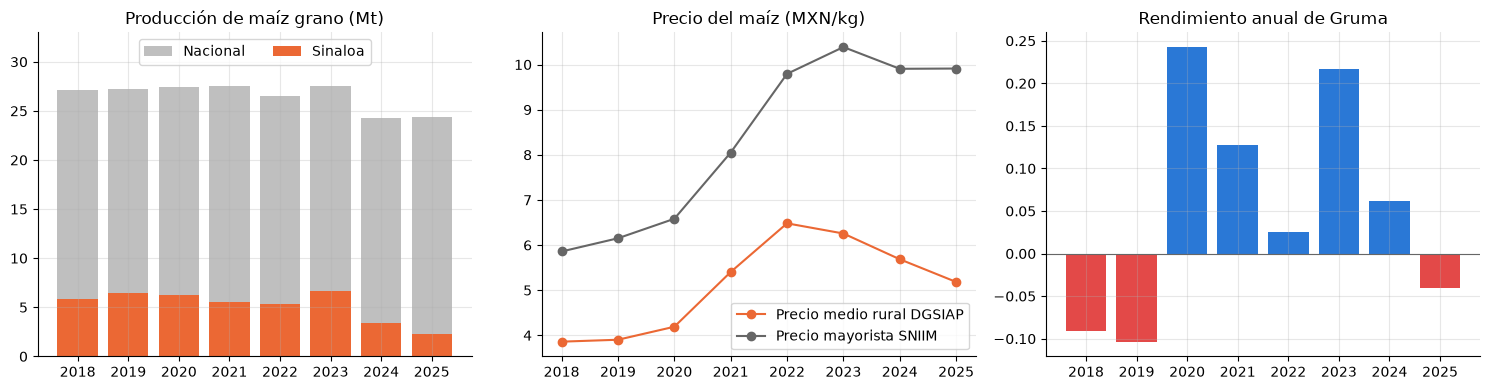

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

ejes[0].bar(anual.index, anual["produccion_mt"], color="0.75", label="Nacional")
ejes[0].bar(anual.index, anual["produccion_sinaloa_mt"], color=COLOR_MAIZ, label="Sinaloa")
ejes[0].set_title("Producción de maíz grano (Mt)")
ejes[0].set_ylim(0, 33)
ejes[0].legend(loc="upper center", ncol=2)

ejes[1].plot(anual.index, anual["precio_rural_mxn_t"] / 1000, marker="o", color=COLOR_MAIZ,
             label="Precio medio rural DGSIAP")
ejes[1].plot(anual.index, anual["precio_sniim_mxn_kg"], marker="o", color="0.4",
             label="Precio mayorista SNIIM")
ejes[1].set_title("Precio del maíz (MXN/kg)")
ejes[1].legend()

colores = [COLOR_GRUMA if v >= 0 else "#e34948" for v in anual["rendimiento_gruma"]]
ejes[2].bar(anual.index, anual["rendimiento_gruma"], color=colores)
ejes[2].axhline(0, color="0.4", lw=0.8)
ejes[2].set_title("Rendimiento anual de Gruma")

fig.tight_layout()
fig.savefig(ruta_figuras / "cruce_anual_dgsiap_sniim_gruma.png", dpi=150)
plt.show()

In [12]:
# Con solo 8 años la correlación es solo indicativa.
anual.corr(method="spearman").round(2)

,produccion_mt,produccion_sinaloa_mt,precio_rural_mxn_t,precio_sniim_mxn_kg,rendimiento_gruma
produccion_mt,1.00,0.81,-0.02,-0.07,0.48
produccion_sinaloa_mt,0.81,1.00,-0.21,-0.26,0.19
precio_rural_mxn_t,-0.02,-0.21,1.00,0.76,0.45
precio_sniim_mxn_kg,-0.07,-0.26,0.76,1.00,0.40
rendimiento_gruma,0.48,0.19,0.45,0.40,1.00


**Hallazgo.**
- El precio que recibe el productor (DGSIAP) y el precio mayorista (SNIIM) se mueven juntos:
  los dos suben fuerte en 2021–2022 y bajan desde 2023. Esto valida que ambas fuentes cuentan
  la misma historia.
- La sequía de Sinaloa (2024–2025) quitó cerca de 4 Mt de producción, pero **el precio no
  subió**, siguió bajando. El hueco se cubrió con importaciones (el maíz internacional estaba
  barato en 2024–2025), así que la menor producción nacional no se tradujo en maíz más caro.
- Gruma no muestra un patrón claro contra la producción ni contra el precio a nivel anual. Con
  8 puntos cualquier correlación es frágil, así que no la usamos para concluir.

## Zoom regional: la sequía en Sinaloa y el mercado de Culiacán

Si la sequía tuvo efecto en precios debería verse primero en Culiacán, que es el mercado del
estado productor.

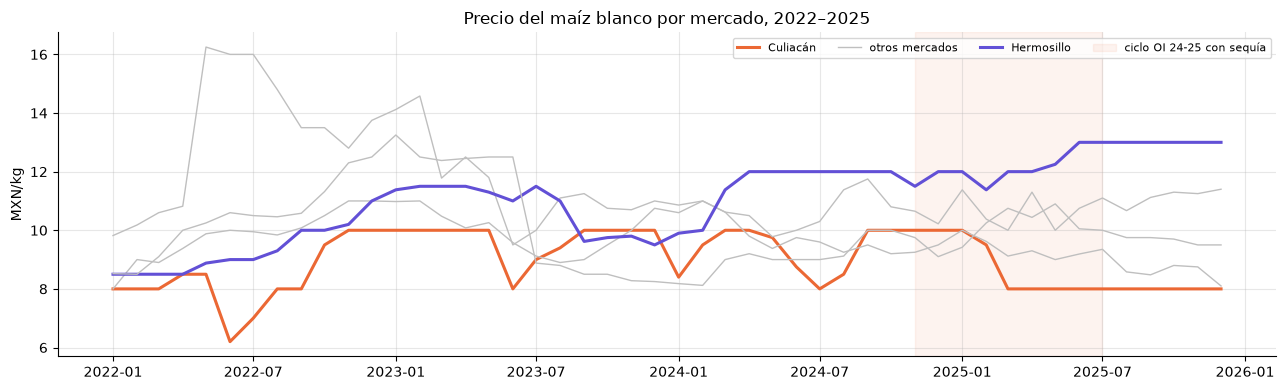

In [13]:
zoom = precio_mercado.loc["2022":"2025"]

fig, eje = plt.subplots(figsize=(13, 4))
for mercado in zoom.columns:
    if mercado == "Culiacán":
        eje.plot(zoom.index, zoom[mercado], color=COLOR_MAIZ, lw=2.2, label=mercado)
    elif mercado == "Hermosillo":
        eje.plot(zoom.index, zoom[mercado], color="#6250d6", lw=2.2, label=mercado)
    else:
        eje.plot(zoom.index, zoom[mercado], color="0.75", lw=1, label="otros mercados" if mercado == "Guadalajara" else None)
eje.axvspan("2024-11-01", "2025-06-30", color=COLOR_MAIZ, alpha=0.08, label="ciclo OI 24-25 con sequía")
eje.set_ylabel("MXN/kg")
eje.set_title("Precio del maíz blanco por mercado, 2022–2025")
eje.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**Hallazgo.** Culiacán es el mercado más barato todo el periodo (está junto a la zona
productora) y no se dispara durante la sequía; al contrario, baja a 8 MXN/kg en 2025. Hermosillo sí se separa hacia arriba en
2025 (13 MXN/kg), lo que podría reflejar que Sonora dejó de recibir maíz barato de Sinaloa, pero es un
solo mercado y no lo podemos confirmar con estos datos.

## Conclusiones

1. **Los eventos sí se ven en el maíz, no tanto en Gruma.** El choque de 2021–2022 (pandemia,
   Ucrania) casi duplicó el precio del maíz según el SNIIM y el DGSIAP, y la invasión a Ucrania
   es el único evento donde maíz y Gruma se mueven fuerte a la vez (maíz +16 %, Gruma −15 %).
   Los eventos regulatorios (transgénicos, panel del T-MEC) no dejan huella clara.
2. **Lo que más mueve a Gruma no es el maíz.** Sus movimientos fuertes coinciden con eventos de
   mercado general, comercio y tipo de cambio (TLCAN, COVID, aranceles de EU en 2025). Tiene
   sentido: más de la mitad de sus ventas son en EU.
3. **Mes a mes no hay relación.** El cambio del precio regional del maíz no se correlaciona con
   el rendimiento de Gruma, ni en el mismo mes ni con 1 a 3 meses de rezago. Para la pregunta
   del proyecto, este es el hallazgo principal: **la relación es débil o nula** a nivel mensual.
4. **Producción ≠ precio.** La caída de producción por la sequía de Sinaloa (2024–2025) no subió
   el precio; el mercado se abasteció con importaciones. Para explicar el precio del maíz en
   México parece pesar más el precio internacional que la cosecha nacional.
5. **A nivel anual hay algo, pero con 8 puntos.** Los años con maíz más caro (2020–2023) fueron
   años positivos para Gruma (Spearman ≈ 0.4), lo contrario a lo esperado si el maíz fuera solo
   un costo. Una lectura posible: Gruma traslada el costo al precio de la tortilla y la harina.
   Con 8 años no es concluyente.
6. **Limitaciones.** El DGSIAP solo da 8 años, el SNIIM tiene huecos (junio 2020) y los eventos
   tienen fechas aproximadas. Nada de esto es causal.

**Siguiente paso sugerido:** agregar el tipo de cambio (INEGI) y un precio internacional del
maíz (futuros de Chicago) como variables de contexto. Con lo visto aquí, probablemente explican
más de Gruma que el precio regional del maíz.